# 10 — Detecção de objetos com Haar Cascade

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 10/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 10/16

> **Execução:** ainda não confirmada nesta versão; reinicie o kernel e execute as células obrigatórias localmente.


### Materiais complementares

- [Guia Técnico](./reference_materials/10_detector_haar_cascade.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_detector_haar_cascade.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Compreender cascatas, janelas deslizantes e uma inferência local com OpenCV.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Uma cascata Haar utiliza características retangulares eficientes e estágios de rejeição progressiva. Foi muito usada para detectar rostos; desempenho varia com pose, iluminação e escala. Detectar retorna caixas candidatas, não identidades. A implementação deve conferir disponibilidade do arquivo XML da cascata.

### Conceito matemático

$$f_{Haar}=\sum I_{região\ clara}-\sum I_{região\ escura}$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
import cv2
from skimage.data import astronaut
img=cv2.cvtColor(astronaut(),cv2.COLOR_RGB2GRAY)
from pathlib import Path
xml = Path(cv2.data.haarcascades) / 'haarcascade_frontalface_default.xml'
if not xml.is_file():
    raise FileNotFoundError(
        f'Cascata XML não encontrada: {xml}. '
        'Confira a versão do opencv-contrib-python (validada: 4.13.0.92).'
    )
face = cv2.CascadeClassifier(str(xml))
if face.empty():
    raise RuntimeError(f'Falha ao carregar a cascata: {xml}')
boxes=face.detectMultiScale(img,scaleFactor=1.1,minNeighbors=5,minSize=(25,25))
print('Candidatos de face:',len(boxes),'formato:',boxes.shape)

Candidatos de face: 1 formato: (1, 4)


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

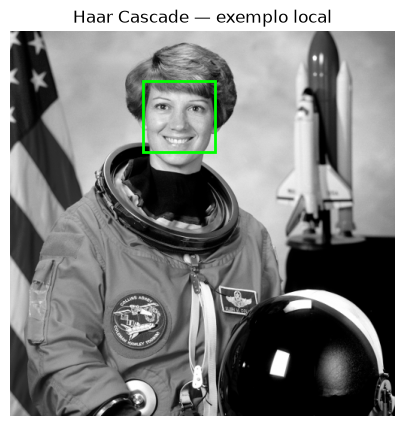

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
fig,ax=plt.subplots(figsize=(5,5));ax.imshow(img,cmap='gray')
for x,y,w,h in boxes:ax.add_patch(Rectangle((x,y),w,h,fill=False,edgecolor='lime',linewidth=2))
ax.set_title('Haar Cascade — exemplo local');ax.axis('off');plt.show()

## Interpretação técnica

A ferramenta encontra caixas aproximadas, mas não demonstra taxa de falso positivo nem validação populacional.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Qual o efeito geral de aumentar minNeighbors?

**Resolução comentada:** Tende a tornar a detecção mais conservadora, reduzindo certas falsas detecções e podendo perder faces.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

Usar imagem demonstrativa pública da biblioteca; não capturar webcam nem identificar pessoas.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Compreender cascatas, janelas deslizantes e uma inferência local com OpenCV.
- **Mecanismo:** Uma cascata Haar utiliza características retangulares eficientes e estágios de rejeição progressiva.
- **Equação:** $f_{Haar}=\sum I_{região\ clara}-\sum I_{região\ escura}$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** XML e falsa detecção. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **XML e falsa detecção** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Laboratório adicional — Cascata Haar: validação antes do carregamento

Experimento independente do estado das células anteriores. Use-o como verificação e explique seus limites; resultados em conjuntos sintéticos não são estimativas de desempenho real.

In [3]:
from pathlib import Path
try:
 import cv2
 xml=Path(cv2.data.haarcascades)/'haarcascade_frontalface_default.xml'
 print('OpenCV:',cv2.__version__,'XML presente:',xml.is_file())
 if xml.is_file():
  detector=cv2.CascadeClassifier(str(xml))
  assert not detector.empty()
  print('Detector carregado')
except ImportError:
 print('OpenCV ausente: instalação opcional conforme guia.')

OpenCV: 4.13.0 XML presente: True
Detector carregado


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **XML e falsa detecção** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
